[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/08_equilibration_production.ipynb)

# 08 · Equilibration (NVT → NPT with Restraints) and Production

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~60 min*

After minimization the atoms sit still in a strained-free but *cold* structure, and the water has not yet
adjusted to the protein. **Equilibration** brings the system gently to the target temperature and pressure
while position restraints keep the protein close to the experimental structure. Then the restraints are
released and the **production** run records the trajectory we analyse. This notebook runs the complete
protocol on solvated chignolin, with reporters, trajectory output, and checkpoint/restart, the way you would
on a cluster.

**Learning objectives.** By the end of this notebook you will be able to:

- add harmonic position restraints and switch them off cleanly
- run NVT then NPT equilibration and judge convergence from temperature, density, and energy
- attach reporters for logs, trajectories (DCD), and checkpoints, and restart from a checkpoint
- measure performance in ns/day and estimate the cost of a real study

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm', 'pdbfixer', 'mdtraj'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


The runs here are deliberately short (tens of picoseconds) so the notebook finishes in a few minutes on a laptop
or free Colab. Real protocols use 100 ps–1 ns for each equilibration stage and 100 ns or more of production; the
precomputed 3 × 0.2 ns trajectories in `data/` (shown at the end) were made with this protocol and the
script `scripts/generate_trajectories.py`.

## 1. Build and minimize the system (recap of Notebook 07)

In [2]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmm
from openmm import app, unit
from pdbfixer import PDBFixer

NVT_PS, NPT_PS, PROD_PS = 20, 20, 40      # increase these for real work (e.g. 100, 100, 100000)
DT = 0.004                                 # ps: 4 fs, allowed by HBonds constraints + HMR (Notebook 03)
os.makedirs("output", exist_ok=True)

fixer = PDBFixer(filename=f"{DATA_DIR}/structures/5AWL.pdb")
fixer.removeHeterogens(keepWater=False); fixer.findMissingResidues(); fixer.findMissingAtoms(); fixer.addMissingAtoms()
ff = app.ForceField("amber14-all.xml", "amber14/tip3pfb.xml")
model = app.Modeller(fixer.topology, fixer.positions)
model.addHydrogens(ff, pH=7.0)
protein_idx = [a.index for a in model.topology.atoms()]
model.addSolvent(ff, padding=1.0 * unit.nanometer, ionicStrength=0.15 * unit.molar)

system = ff.createSystem(model.topology, nonbondedMethod=app.PME, nonbondedCutoff=1.0 * unit.nanometer,
                         constraints=app.HBonds, hydrogenMass=1.5 * unit.amu)
print(f"{model.topology.getNumAtoms()} atoms, {system.getNumConstraints()} constraints")

3240 atoms, 3139 constraints


## 2. Position restraints

A restraint is just an extra energy term, $E = \tfrac12 k\,|\mathbf{r}_i - \mathbf{r}_i^0|^2$, on selected atoms
(here the peptide's heavy atoms) that pulls them back towards their starting positions. We implement it with a
`CustomExternalForce` and control its strength `k` through a **global parameter**, so we can switch it off later
without rebuilding anything. `periodicdistance` keeps it correct across the periodic boundary.

In [3]:
restraint = openmm.CustomExternalForce("0.5*k_restr*periodicdistance(x, y, z, x0, y0, z0)^2")
restraint.addGlobalParameter("k_restr", 1000.0)          # kJ/mol/nm^2
for p in ("x0", "y0", "z0"):
    restraint.addPerParticleParameter(p)
heavy = [i for i in protein_idx if list(model.topology.atoms())[i].element.symbol != "H"]
for i in heavy:
    restraint.addParticle(i, model.positions[i].value_in_unit(unit.nanometer))
system.addForce(restraint)

barostat = openmm.MonteCarloBarostat(1.0 * unit.bar, 300 * unit.kelvin, 25)
barostat.setFrequency(0)                                 # off during NVT; switched on for NPT
system.addForce(barostat)

integrator = openmm.LangevinMiddleIntegrator(300 * unit.kelvin, 1 / unit.picosecond, DT * unit.picoseconds)
integrator.setRandomNumberSeed(2024)
sim = app.Simulation(model.topology, system, integrator, openmm.Platform.getPlatformByName("CPU"))
sim.context.setPositions(model.positions)
t0 = time.time()
sim.minimizeEnergy()
print(f"restrained heavy atoms: {len(heavy)} | minimized in {time.time() - t0:.0f} s, "
      f"E = {sim.context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole):.0f} kJ/mol")

restrained heavy atoms: 93 | minimized in 29 s, E = -63206 kJ/mol


## 3. NVT equilibration: heat to 300 K

We draw random velocities for 300 K and let the Langevin thermostat settle the temperature. A
`StateDataReporter` writes a log line every 0.4 ps (to a CSV file and, more sparsely, to the screen).

In [4]:
sim.context.setVelocitiesToTemperature(300 * unit.kelvin, 2024)
log_kw = dict(step=True, time=True, potentialEnergy=True, temperature=True, volume=True, density=True, speed=True)
sim.reporters = [app.StateDataReporter("output/nvt.csv", 100, **log_kw),
                 app.StateDataReporter(sys.stdout, 1000, step=True, temperature=True, speed=True)]
t0 = time.time()
sim.step(int(NVT_PS / DT))
print(f"NVT {NVT_PS} ps done in {time.time() - t0:.0f} s")

#"Step","Temperature (K)","Speed (ns/day)"


1000,306.69590775975365,0


2000,294.49081628651356,51.5


3000,300.19525146689824,55.2


4000,299.69361948017774,57.7


5000,291.686472438176,58.4


NVT 20 ps done in 30 s


## 4. NPT equilibration: let the density adjust

Switch the barostat on (frequency 25 steps). The box volume, and therefore the water density, relaxes to
1 bar. The restraints stay on.

NPT 20 ps done in 32 s


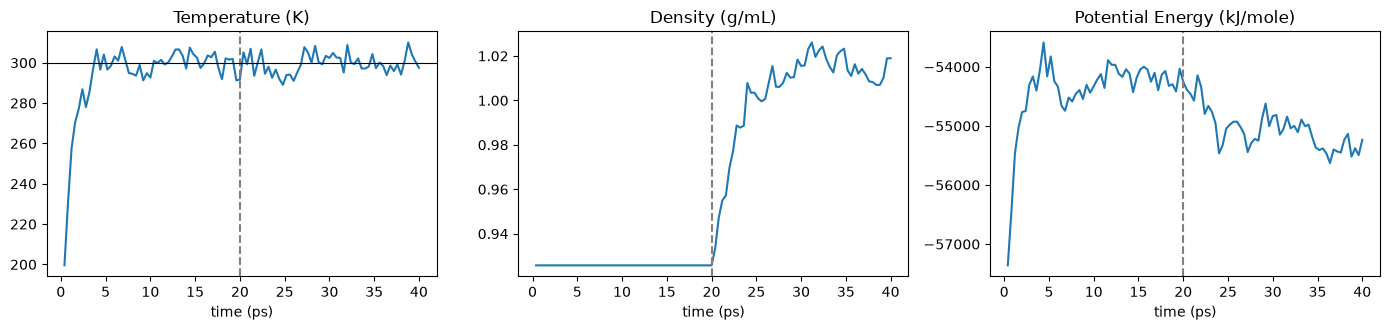

      Temperature (K)  Density (g/mL)
mean         300.1122          1.0160
std            4.1201          0.0058


In [5]:
barostat.setFrequency(25)
sim.context.reinitialize(preserveState=True)              # apply the changed barostat setting
sim.reporters = [app.StateDataReporter("output/npt.csv", 100, **log_kw)]
t0 = time.time()
sim.step(int(NPT_PS / DT))
print(f"NPT {NPT_PS} ps done in {time.time() - t0:.0f} s")

nvt, npt = pd.read_csv("output/nvt.csv"), pd.read_csv("output/npt.csv")
eq = pd.concat([nvt, npt])
tcol = '#"Time (ps)"' if '#"Time (ps)"' in eq else eq.columns[1]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a_, col in zip(ax, ["Temperature (K)", "Density (g/mL)", "Potential Energy (kJ/mole)"]):
    a_.plot(eq[tcol], eq[col]); a_.axvline(NVT_PS, color="grey", ls="--"); a_.set(xlabel="time (ps)", title=col)
ax[0].axhline(300, color="k", lw=0.8)
plt.tight_layout(); plt.show()
print(npt[["Temperature (K)", "Density (g/mL)"]].tail(25).describe().loc[["mean", "std"]].round(4))

**Is it equilibrated?** Look for quantities that stop drifting and fluctuate around a stable mean: temperature
(within seconds), density (tens of ps for a small box), potential energy. With our very short stages the density
may still be creeping; on a real project you extend NPT until it is flat. Structural properties (RMSD,
secondary structure) take much longer, which is why the first part of production is often discarded too
(Notebook 12).

## 5. Production: release the restraints and record the trajectory

Setting `k_restr` to zero turns the restraints off instantly. We attach three reporters:

- `DCDReporter` writes coordinates every 2 ps. With `atomSubset` we save only the peptide, which keeps the
  file tiny (water is usually not needed for analysis; keep it if you study solvation).
- `StateDataReporter` logs thermodynamics.
- `CheckpointReporter` saves a binary checkpoint every 10 ps so that a crashed or time-limited job can resume.

In [6]:
sim.context.setParameter("k_restr", 0.0)
sim.currentStep = 0
sim.reporters = [
    app.DCDReporter("output/production.dcd", 500, atomSubset=protein_idx),
    app.StateDataReporter("output/production.csv", 250, **log_kw),
    app.CheckpointReporter("output/production.chk", 2500),
]
t0 = time.time()
sim.step(int(PROD_PS / DT))
wall = time.time() - t0
ns_day = PROD_PS / 1000 / wall * 86400
print(f"production {PROD_PS} ps in {wall:.0f} s  ->  {ns_day:.1f} ns/day on this machine")
print(f"1 microsecond would take about {1000 / ns_day:.0f} days here")

production 40 ps in 78 s  ->  44.3 ns/day on this machine
1 microsecond would take about 23 days here


That last line is why MD lives on GPUs and clusters: the same system runs at hundreds of ns/day on a single
modern GPU. To use one with OpenMM you only change the platform name to `"CUDA"` (Notebook 12 covers HPC).

## 6. Restarting from a checkpoint

Clusters impose wall-time limits, so long runs are split into chunks. A checkpoint stores positions, velocities,
box, step count, and even the random-number state, so the continuation is seamless.

In [7]:
print("step before restart:", sim.currentStep)
sim2 = app.Simulation(model.topology, system, openmm.LangevinMiddleIntegrator(300, 1, DT),
                      openmm.Platform.getPlatformByName("CPU"))
sim2.loadCheckpoint("output/production.chk")
st = sim2.context.getState(getEnergy=True)
print(f"restarted at step {sim2.currentStep}, time {st.getTime().value_in_unit(unit.picosecond):.1f} ps, "
      f"k_restr = {sim2.context.getParameter('k_restr')}")
sim2.step(500)
print("continued to step", sim2.currentStep)

step before restart: 10000
restarted at step 10000, time 80.0 ps, k_restr = 0.0


continued to step 10500


A checkpoint is tied to the platform and OpenMM version that wrote it. For portable restarts use
`sim.saveState("file.xml")` / `sim.loadState(...)`, which store the same information as XML.

## 7. Read the trajectory back

The DCD file contains only coordinates; the topology comes from a PDB of the same atoms.

In [8]:
import mdtraj as md

top_pdb = "output/chignolin_protein.pdb"
pos = sim.context.getState(getPositions=True).getPositions()
sub = app.Modeller(model.topology, pos)
sub.delete([r for r in sub.topology.residues() if r.name in ("HOH", "NA", "CL")])
app.PDBFile.writeFile(sub.topology, sub.positions, open(top_pdb, "w"))

traj = md.load("output/production.dcd", top=top_pdb)
print(traj)
rmsd_nm = md.rmsd(traj, md.load(top_pdb), atom_indices=traj.topology.select("name CA"))
print(f"C-alpha RMSD from the final frame: first frame {rmsd_nm[0] * 10:.2f} Å, mean {rmsd_nm.mean() * 10:.2f} Å")

<mdtraj.Trajectory with 20 frames, 166 atoms, 10 residues, and unitcells>
C-alpha RMSD from the final frame: first frame 0.25 Å, mean 0.30 Å


## 8. The precomputed production runs

`data/trajectories/` holds three independent 0.2 ns production runs of the same system (different random seeds),
made with this protocol (20 ps NVT + 20 ps NPT with restraints, then NPT production at 4 fs). Their
thermodynamic log looks like this; Notebook 09 analyses the structures.

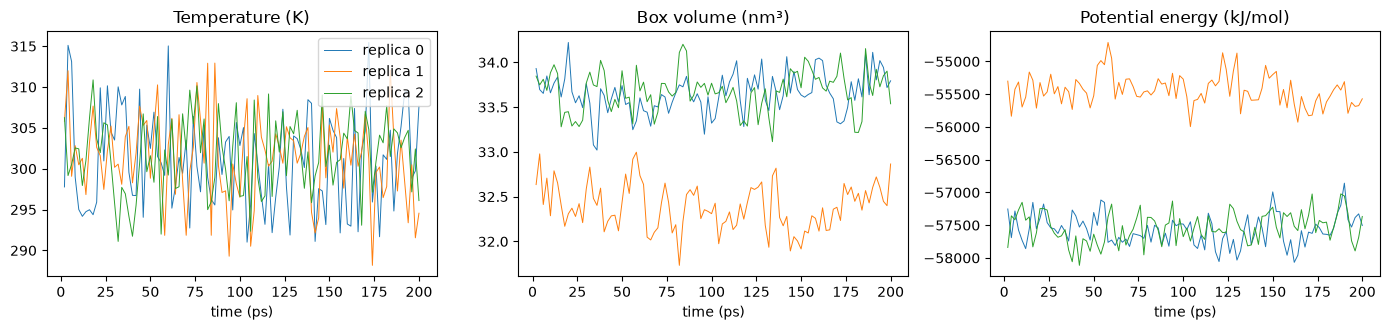

temperature_K       volume_nm3       potential_kJmol        
                 mean   std       mean   std            mean     std
replica                                                             
0              300.98  5.90      33.66  0.22       -57574.88  231.38
1              301.35  5.19      32.39  0.26       -55440.80  236.70
2              301.60  4.58      33.68  0.23       -57532.94  232.77

In [9]:
thermo = pd.read_csv(f"{DATA_DIR}/trajectories/chignolin_thermo.csv")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for rep, g in thermo.groupby("replica"):
    for a_, col in zip(ax, ["temperature_K", "volume_nm3", "potential_kJmol"]):
        a_.plot(g.time_ps, g[col], lw=0.7, label=f"replica {rep}")
for a_, t in zip(ax, ["Temperature (K)", "Box volume (nm³)", "Potential energy (kJ/mol)"]):
    a_.set(xlabel="time (ps)", title=t)
ax[0].legend(); plt.tight_layout(); plt.show()
thermo.groupby("replica")[["temperature_K", "volume_nm3", "potential_kJmol"]].agg(["mean", "std"]).round(2)

All three replicas hold the target temperature. Their box volumes and potential energies differ by a near-constant
offset, which is **not** a sign of a problem: each replica was solvated independently and received a slightly
different number of water molecules (3258–3387 atoms in total, see `data/provenance.json`). Absolute energies and
volumes are only comparable between simulations with identical composition; within one replica, what matters is
that they fluctuate around a stable mean.

### ✏️ Exercise 1

Using the NPT log (`npt`), compute the mean density over the first and the second half of the NPT stage. Is the
difference larger than the standard deviation within each half? What would you do on a real project?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
half = len(npt) // 2
a, b = npt["Density (g/mL)"].iloc[:half], npt["Density (g/mL)"].iloc[half:]
print(f"first half {a.mean():.4f} ± {a.std():.4f}, second half {b.mean():.4f} ± {b.std():.4f}")
# If the means differ by more than the noise, the density is still drifting: extend NPT equilibration.
```

</details>

### ✏️ Exercise 2

What is the end-to-end distance (Tyr1 N to Tyr10 C) in each
frame of your short production trajectory? Use `md.compute_distances`.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
n_term = traj.topology.select("resid 0 and name N")[0]
c_term = traj.topology.select("resid 9 and name C")[0]
d = md.compute_distances(traj, [[n_term, c_term]])[:, 0]
print(f"end-to-end distance: mean {d.mean():.3f} nm, min {d.min():.3f}, max {d.max():.3f}")
```

</details>

### ✏️ Exercise 3

Restraint strength matters. Measure how far the restrained heavy atoms moved during NVT + NPT: compute the RMSD
of the heavy atoms between the starting coordinates `model.positions` and the last NPT frame. Then explain why we
did not simply keep the restraints on during production.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
X0 = np.array(model.positions.value_in_unit(unit.nanometer))[heavy]
# reconstruct the end-of-NPT positions from the first production frame of the DCD (2 ps after release)
X1 = traj.xyz[0][[protein_idx.index(i) for i in heavy]]
print(f"heavy-atom RMS displacement: {np.sqrt(((X1 - X0) ** 2).sum(1).mean()) * 10:.2f} Å (no fitting)")
# Restraints bias the dynamics: production must be unrestrained to sample the real ensemble.
```

</details>

## Key takeaways

- Equilibrate in stages: minimize → NVT (heat) → NPT (density), with position restraints on the solute.
- Judge equilibration by plateaus in temperature, density, and energy; extend stages when in doubt.
- Production: restraints off, reporters for DCD trajectories, logs, and checkpoints.
- Measure ns/day early; it determines what science is feasible on your hardware.

**Next:** [09 · Trajectory analysis with MDAnalysis and MDTraj](09_trajectory_analysis.ipynb).